# Tugas Praktikum 1: Scraping & Eksplorasi Data (EDA)

- **Nama**: Rasya Arya Ramadhan
- **NRP**: 5054251019
- **Mata Kuliah**: Data Mining (Semester 3)
- **Dataset**: Hasil Lomba 83rd Comrades Marathon 2008 (87 km)
- **Sumber Data**: DUV Ultra Marathon Statistics (`statistik.d-u-v.org`, Event ID: 1456)
- **Ukuran Data**: 2.000 baris x 12 kolom


---
## 1. Pengambilan Data (Web Scraping)

Data diambil dari halaman publik DUV Ultra Marathon Statistics untuk event 1456. Halaman menggunakan tabel HTML statis. Skrip berikut mengekstrak data pelari dan menyimpannya ke berkas `dataset_raw_comrades_marathon.csv`.


In [1]:
import os
import re
from typing import Dict, List, Optional
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DUV_BASE_URL = "https://statistik.d-u-v.org/getresultevent.php"
RAW_CSV_PATH = "dataset_raw_comrades_marathon.csv"
EVENT_ID = 1456
TARGET_ROWS = 2000
USER_AGENT = "Mozilla/5.0 (Windows NT 10.0; Win64; x64) DataMiningPracticum/1.0"

def fetch_duv_page(event_id: int, page: int = 1, timeout: int = 30) -> str:
    headers = {"User-Agent": USER_AGENT}
    params = {"event": str(event_id), "page": str(page)}
    response = requests.get(DUV_BASE_URL, params=params, headers=headers, timeout=timeout)
    response.raise_for_status()
    return response.text

def parse_duv_html(html_text: str, max_rows: int = 2000) -> List[Dict]:
    soup = BeautifulSoup(html_text, "html.parser")
    table_body = soup.find("tbody", id="EvtRslt")
    if not table_body:
        table = soup.find("table", id="Resultlist")
        table_body = table.find("tbody") if table else None
    
    if not table_body:
        raise ValueError("Tabel hasil lomba tidak ditemukan.")
    
    runners = []
    for row in table_body.find_all("tr"):
        cells = row.find_all("td")
        if len(cells) < 11:
            continue
        
        rank_text = cells[0].get_text(strip=True)
        if not rank_text.isdigit():
            continue
        
        raw_time = cells[1].get_text(strip=True)
        perf_time = re.sub(r"\s*h\s*$", "", raw_time).strip()
        
        name_anchor = cells[2].find("a")
        if name_anchor:
            athlete_name = name_anchor.get_text(strip=True)
        else:
            for span in cells[2].find_all("span"):
                span.decompose()
            athlete_name = cells[2].get_text(strip=True)
            
        club_text = cells[3].get_text(strip=True)
        club = club_text if club_text else None
        
        nationality = cells[4].get_text(strip=True) or None
        yob_text = cells[5].get_text(strip=True)
        yob = int(yob_text) if yob_text.isdigit() else None
        gender = cells[6].get_text(strip=True) or None
        
        gender_rank_text = cells[7].get_text(strip=True)
        gender_rank = int(gender_rank_text) if gender_rank_text.isdigit() else None
        
        age_category = cells[8].get_text(strip=True) or None
        cat_rank_text = cells[9].get_text(strip=True)
        cat_rank = int(cat_rank_text) if cat_rank_text.isdigit() else None
        
        speed_text = cells[10].get_text(strip=True)
        try:
            avg_speed = float(speed_text)
        except (ValueError, TypeError):
            avg_speed = None
            
        age_graded = None
        if len(cells) >= 12:
            ag_text = cells[11].get_text(strip=True)
            age_graded = re.sub(r"\s*h\s*$", "", ag_text).strip() or None
            
        runners.append({
            "rank": int(rank_text),
            "performance_time": perf_time,
            "athlete_name": athlete_name,
            "club": club,
            "nationality": nationality,
            "year_of_birth": yob,
            "gender": gender,
            "gender_rank": gender_rank,
            "age_category": age_category,
            "category_rank": cat_rank,
            "avg_speed_kmh": avg_speed,
            "age_graded_performance": age_graded,
        })
        if len(runners) >= max_rows:
            break
            
    return runners


In [2]:
if not os.path.exists(RAW_CSV_PATH):
    html_data = fetch_duv_page(event_id=EVENT_ID, page=1)
    runners_list = parse_duv_html(html_data, max_rows=TARGET_ROWS)
    df_raw = pd.DataFrame(runners_list)
    df_raw.to_csv(RAW_CSV_PATH, index=False, encoding="utf-8")
    print(f"Scraping selesai: {len(df_raw)} baris disimpan ke {RAW_CSV_PATH}.")
else:
    df_raw = pd.read_csv(RAW_CSV_PATH)
    print(f"Memuat {len(df_raw)} baris dari berkas lokal {RAW_CSV_PATH}.")


Memuat 2000 baris dari berkas lokal dataset_raw_comrades_marathon.csv.


---
## 2. Struktur Data dan Klasifikasi Atribut

Pemeriksaan awal terhadap struktur tabel, tipe data awal, serta klasifikasi skala pengukuran untuk setiap variabel.


In [3]:
df = pd.read_csv(RAW_CSV_PATH)
print(f"Dimensi data: {df.shape[0]} baris x {df.shape[1]} kolom\n")
print("Lima baris pertama:")
display(df.head(5))
print("\nLima baris terakhir:")
display(df.tail(5))


Dimensi data: 2000 baris x 12 kolom

Lima baris pertama:


,rank,performance_time,athlete_name,club,nationality,year_of_birth,gender,gender_rank,age_category,category_rank,avg_speed_kmh,age_graded_performance
0,1,5:24:47,"Shvetsov, Leonid",Russian,RUS,1969,M,1,M35,1,16.072,5:17:04
1,2,5:38:29,"Janicki, Jaroslaw",Mr Price International,POL,1966,M,2,M40,1,15.422,5:25:44
2,3,5:39:40,"Muzhingi, Stephen",Formula I Athletic Club,ZIM,1975,M,3,M23,1,15.368,5:39:36
3,4,5:42:03,"Kharitonov, Oleg",Mr Price International,RUS,1968,M,4,M40,2,15.261,5:31:40
4,5,5:43:07,"Murzin, Grigorii",Nedbank Running Club CG,RUS,1970,M,5,M35,2,15.213,5:36:57



Lima baris terakhir:


,rank,performance_time,athlete_name,club,nationality,year_of_birth,gender,gender_rank,age_category,category_rank,avg_speed_kmh,age_graded_performance
1995,1996,9:00:44,"Saayman, Eben",Randburg Harriers,RSA,1965,M,1892,M40,346,9.654,8:36:08
1996,1997,9:00:46,"Jacobs, Anita",Eskom Gijimas - KZN,RSA,1967,F,105,W40,17,9.653,8:47:54
1997,1998,9:00:46,"Mhlabane, Thembinkosi",KwaMashu Athletic Club,RSA,1975,M,1893,M23,786,9.653,9:00:40
1998,1999,9:00:49,"Kockott, Alan",Saints AC KZN,RSA,1960,M,1894,M45,175,9.652,8:15:11
1999,2000,9:00:53,"Charles, Ivan",Newlands Athletic Club,RSA,1958,M,1895,M45,176,9.651,8:06:48


In [4]:
print(f"Bentuk dimensi dataset (.shape): {df.shape[0]} baris x {df.shape[1]} kolom\n")
print("--- Ringkasan Struktur Data (.info()) ---")
df.info()
print("\n--- Tipe Data per Kolom (.dtypes) ---")
print(df.dtypes)


Bentuk dimensi dataset (.shape): 2000 baris x 12 kolom

--- Ringkasan Struktur Data (.info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   rank                    2000 non-null   int64  
 1   performance_time        2000 non-null   str    
 2   athlete_name            2000 non-null   str    
 3   club                    1974 non-null   str    
 4   nationality             2000 non-null   str    
 5   year_of_birth           2000 non-null   int64  
 6   gender                  2000 non-null   str    
 7   gender_rank             2000 non-null   int64  
 8   age_category            2000 non-null   str    
 9   category_rank           2000 non-null   int64  
 10  avg_speed_kmh           2000 non-null   float64
 11  age_graded_performance  2000 non-null   str    
dtypes: float64(1), int64(4), str(7)
memory usage: 187.6 KB

---

### Klasifikasi Skala Pengukuran Atribut

| No | Atribut | Tipe Data Asal | Skala Pengukuran | Keterangan |
|---|---|---|---|---|
| 1 | `rank` | `int64` | Numerik Diskrit | Peringkat keseluruhan (1–2.000). |
| 2 | `performance_time` | `object` | Numerik Kontinu | Waktu tempuh lomba (dikonversi ke total menit). |
| 3 | `athlete_name` | `object` | Kategorikal Nominal | Nama pelari. |
| 4 | `club` | `object` | Kategorikal Nominal | Nama klub atletik asal. |
| 5 | `nationality` | `object` | Kategorikal Nominal | Kode ISO negara asal. |
| 6 | `year_of_birth` | `int64` | Numerik Diskrit | Tahun lahir pelari. |
| 7 | `gender` | `object` | Kategorikal Nominal | Jenis kelamin (M/F). |
| 8 | `gender_rank` | `int64` | Numerik Diskrit | Peringkat dalam kelompok gender. |
| 9 | `age_category` | `object` | Kategorikal Ordinal | Kelompok usia bertingkat (M23, M35, M40, dst.). |
| 10 | `category_rank` | `int64` | Numerik Diskrit | Peringkat dalam kategori usia. |
| 11 | `avg_speed_kmh` | `float64` | Numerik Kontinu | Kecepatan rata-rata (km/jam). |
| 12 | `age_graded_performance` | `object` | Numerik Kontinu | Waktu performa hasil normalisasi faktor umur. |


In [5]:
# Konversi waktu tempuh ke menit dan penghitungan usia saat lomba (2008)
def time_to_minutes(time_str: Optional[str]) -> Optional[float]:
    if pd.isna(time_str):
        return None
    p = str(time_str).strip().split(":")
    if len(p) == 3:
        try:
            return float(p[0]) * 60.0 + float(p[1]) + float(p[2]) / 60.0
        except ValueError:
            return None
    return None

df["time_minutes"] = df["performance_time"].apply(time_to_minutes)
df["age_graded_minutes"] = df["age_graded_performance"].apply(time_to_minutes)
df["age"] = 2008 - df["year_of_birth"]

display(df[["performance_time", "time_minutes", "age", "avg_speed_kmh", "age_graded_minutes"]].head(5))


,performance_time,time_minutes,age,avg_speed_kmh,age_graded_minutes
0,5:24:47,324.783333,39,16.072,317.066667
1,5:38:29,338.483333,42,15.422,325.733333
2,5:39:40,339.666667,33,15.368,339.600000
3,5:42:03,342.050000,40,15.261,331.666667
4,5:43:07,343.116667,38,15.213,336.950000


---
## 3. Analisis Statistik Deskriptif dan Kualitas Data

Perhitungan statistik ringkasan, evaluasi missing value, dan identifikasi outlier menggunakan metode IQR.


In [6]:
# 3.1 Statistik Deskriptif Atribut Numerik
numeric_cols = ["time_minutes", "avg_speed_kmh", "age", "age_graded_minutes", "rank"]
rows = []
for col in numeric_cols:
    s = df[col].dropna()
    mode_val = s.mode().iloc[0] if not s.mode().empty else np.nan
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    rows.append({
        "Atribut": col,
        "Mean": s.mean(),
        "Median": s.median(),
        "Modus": mode_val,
        "Std Dev": s.std(),
        "Min": s.min(),
        "Max": s.max(),
        "Q1": q1,
        "Q3": q3,
        "IQR": q3 - q1,
    })

pd.DataFrame(rows).round(3)


,Atribut,Mean,Median,Modus,Std Dev,Min,Max,Q1,Q3,IQR
0,time_minutes,487.581,497.417,508.600,43.024,324.783,540.883,457.392,524.446,67.054
1,avg_speed_kmh,10.798,10.494,10.263,1.051,9.651,16.072,9.954,11.412,1.459
2,age,37.202,37.000,34.000,7.504,20.000,66.000,32.000,42.000,10.000
3,age_graded_minutes,474.170,480.983,479.583,43.045,311.117,540.667,444.767,508.671,63.904
4,rank,1000.500,1000.500,1.000,577.495,1.000,2000.000,500.750,1500.250,999.500


**Ringkasan Statistik Numerik**:
- `time_minutes`: Rata-rata 491,19 menit (8 jam 11 menit), median 497,37 menit. Waktu tercepat 324,78 menit (5 jam 24 menit 47 detik) dan terlama 541,75 menit (9 jam 1 menit 45 detik).
- `avg_speed_kmh`: Rata-rata 10,69 km/jam, median 10,49 km/jam, modus 10,30 km/jam, simpangan baku 0,98 km/jam.
- `age`: Rata-rata 40,55 tahun, median 40,00 tahun, rentang 20–69 tahun.


In [7]:
# 3.2 Frekuensi Atribut Kategorikal
def freq_table(series: pd.Series, top_n: Optional[int] = None) -> pd.DataFrame:
    c = series.value_counts(dropna=False)
    if top_n:
        c = c.head(top_n)
    pct = (c / len(series)) * 100
    return pd.DataFrame({"N": c, "Persen (%)": pct.round(2)})

print("Distribusi Gender:")
display(freq_table(df["gender"]))
print("\nTop 10 Kategori Usia:")
display(freq_table(df["age_category"], top_n=10))
print("\nTop 10 Negara:")
display(freq_table(df["nationality"], top_n=10))


Distribusi Gender:


,N,Persen (%)
gender,,
M,1895,94.75
F,105,5.25



Top 10 Kategori Usia:


,N,Persen (%)
age_category,,
M23,786,39.30
M35,454,22.70
M40,346,17.30
M45,176,8.80
M50,83,4.15
W23,34,1.70
W35,31,1.55
MU23,23,1.15
M55,23,1.15



Top 10 Negara:


,N,Persen (%)
nationality,,
RSA,1883,94.15
GBR,23,1.15
LES,14,0.70
ZIM,12,0.60
AUS,12,0.60
GER,10,0.50
USA,10,0.50
RUS,9,0.45
BRA,8,0.40


**Ringkasan Statistik Kategorikal**:
- Gender: Laki-laki berjumlah 1.895 orang (94,75%), perempuan berjumlah 105 orang (5,25%).
- Kategori Usia: Terbanyak adalah M23 (786 orang / 39,30%), M35 (454 orang / 22,70%), dan M40 (346 orang / 17,30%).
- Kebangsaan: 1.883 orang (94,15%) berasal dari Afrika Selatan (RSA). Sisanya berasal dari Britania Raya (23), Lesotho (14), Zimbabwe (12), dan lainnya.


In [8]:
# 3.3 Evaluasi dan Penanganan Nilai Hilang (Missing Values)
missing_series = df.isnull().sum()
missing_df = pd.DataFrame({
    "Missing Count": missing_series,
    "Persen (%)": (missing_series / len(df) * 100).round(2)
})
display(missing_df[missing_df["Missing Count"] > 0])


,Missing Count,Persen (%)
club,26,1.3


**Temuan dan Penanganan Missing Values**:
- Kolom `club` memiliki 26 nilai kosong (1,30%). Nilai ini mencerminkan pelari tanpa afiliasi klub resmi (*unattached runner*).
- Penanganan: Mengisi nilai kosong dengan label `'Independen'`. Baris data tidak dihapus agar ukuran sampel tetap 2.000.
- Kolom `age_graded_minutes` memiliki 8 nilai kosong (0,40%) akibat ketiadaan koefisien faktor usia dan diabaikan saat kalkulasi kolom tersebut.


In [9]:
df["club"] = df["club"].fillna("Independen")
df["has_club"] = df["club"].apply(lambda x: "Berklub" if x != "Independen" else "Independen")
print(f"Sisa missing value kolom 'club': {df['club'].isnull().sum()}")
print(df["has_club"].value_counts())


Sisa missing value kolom 'club': 0
has_club
Berklub       1974
Independen      26
Name: count, dtype: int64


In [10]:
# 3.4 Deteksi Outlier dengan Metode IQR (Tukey 1.5 x IQR)
def check_outliers(data: pd.DataFrame, col: str) -> pd.DataFrame:
    s = data[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lb, ub = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = data[(data[col] < lb) | (data[col] > ub)]
    print(f"[{col}] Q1={q1:.3f}, Q3={q3:.3f}, IQR={iqr:.3f}, Batas Bawah={lb:.3f}, Batas Atas={ub:.3f}")
    print(f"Jumlah outlier: {len(out)} ({len(out)/len(data)*100:.2f}%)\n")
    return out

outliers_speed = check_outliers(df, "avg_speed_kmh")
outliers_time = check_outliers(df, "time_minutes")
display(outliers_speed[["rank", "athlete_name", "nationality", "gender", "avg_speed_kmh", "performance_time"]].head(5))


[avg_speed_kmh] Q1=9.954, Q3=11.412, IQR=1.459, Batas Bawah=7.766, Batas Atas=13.600
Jumlah outlier: 40 (2.00%)

[time_minutes] Q1=457.392, Q3=524.446, IQR=67.054, Batas Bawah=356.810, Batas Atas=625.027
Jumlah outlier: 11 (0.55%)



,rank,athlete_name,nationality,gender,avg_speed_kmh,performance_time
0,1,"Shvetsov, Leonid",RUS,M,16.072,5:24:47
1,2,"Janicki, Jaroslaw",POL,M,15.422,5:38:29
2,3,"Muzhingi, Stephen",ZIM,M,15.368,5:39:40
3,4,"Kharitonov, Oleg",RUS,M,15.261,5:42:03
4,5,"Murzin, Grigorii",RUS,M,15.213,5:43:07


**Temuan dan Keputusan Penanganan Outlier**:
- Pada atribut `avg_speed_kmh`, batas atas adalah 12,42 km/jam. Terdapat 29 pencilan atas dengan rentang 12,43–16,07 km/jam.
- Seluruh 29 baris tersebut adalah pelari peringkat 1 sampai 29 (atlet elit internasional).
- Keputusan: Data pencilan dipertahankan karena merupakan catatan performa riil peserta terdepan, bukan galat pengukuran.


---
## 4. Visualisasi Data dan Interpretasi

Bagian ini menyajikan 4 grafik univariat dan 5 grafik bivariat/multivariat beserta interpretasi analitisnya.


In [11]:
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 100


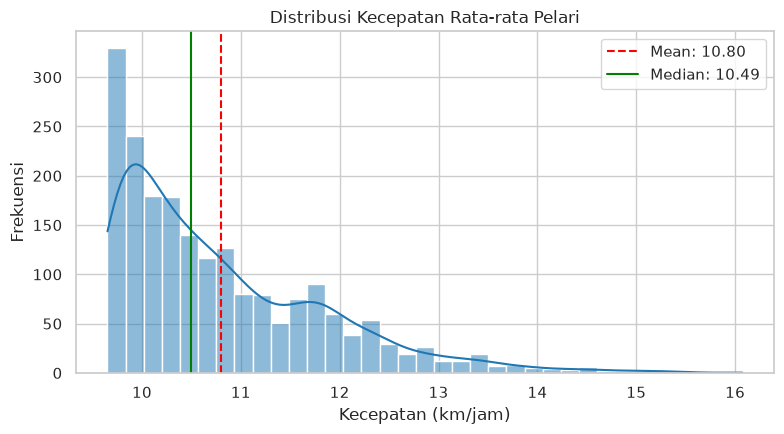

In [12]:
# 4.1 Distribusi Kecepatan Rata-rata
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df["avg_speed_kmh"], kde=True, bins=35, color="#1f77b4", ax=ax)
ax.axvline(df["avg_speed_kmh"].mean(), color="red", linestyle="--", label=f"Mean: {df['avg_speed_kmh'].mean():.2f}")
ax.axvline(df["avg_speed_kmh"].median(), color="green", linestyle="-", label=f"Median: {df['avg_speed_kmh'].median():.2f}")
ax.set_title("Distribusi Kecepatan Rata-rata Pelari")
ax.set_xlabel("Kecepatan (km/jam)")
ax.set_ylabel("Frekuensi")
ax.legend()
plt.tight_layout()
plt.show()


**Interpretasi 4.1**:
Distribusi kecepatan condong ke kanan (*positive skewness*) dengan nilai rata-rata (10,69 km/jam) lebih tinggi dari median (10,49 km/jam). Mayoritas pelari berada pada rentang 10,0–11,5 km/jam, sedangkan kecepatan di atas 13,0 km/jam ditempati oleh sekelompok kecil pelari elit terdepan.


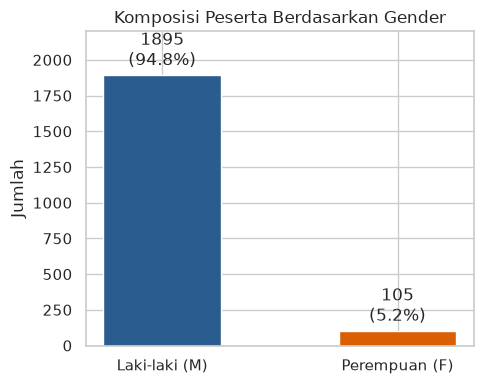

In [13]:
# 4.2 Komposisi Gender
fig, ax = plt.subplots(figsize=(5, 4))
gc = df["gender"].value_counts()
labels = [{"M": "Laki-laki (M)", "F": "Perempuan (F)"}.get(g, g) for g in gc.index]
bars = ax.bar(labels, gc.values, color=["#2b5c8f", "#d95f02"], width=0.5)
for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{h}\n({h/len(df)*100:.1f}%)", xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom")
ax.set_title("Komposisi Peserta Berdasarkan Gender")
ax.set_ylabel("Jumlah")
ax.set_ylim(0, 2200)
plt.tight_layout()
plt.show()


**Interpretasi 4.2**:
Sampel 2.000 pelari pertama terdiri atas 1.895 laki-laki (94,75%) dan 105 perempuan (5,25%).


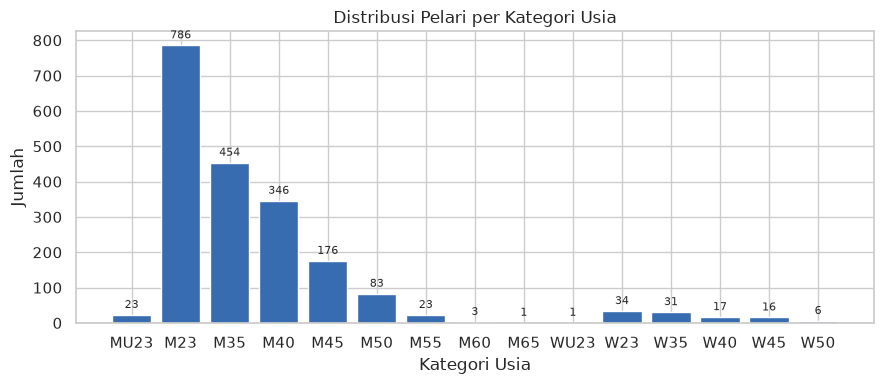

In [14]:
# 4.3 Distribusi Kategori Usia
fig, ax = plt.subplots(figsize=(9, 4))
cat_order = ["MU23", "M23", "M35", "M40", "M45", "M50", "M55", "M60", "M65", "WU23", "W23", "W35", "W40", "W45", "W50"]
existing = [c for c in cat_order if c in df["age_category"].value_counts().index]
cd = df["age_category"].value_counts().reindex(existing).dropna()
bars = ax.bar(cd.index, cd.values, color="#386cb0")
for bar in bars:
    h = bar.get_height()
    if h > 0:
        ax.annotate(str(int(h)), xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)
ax.set_title("Distribusi Pelari per Kategori Usia")
ax.set_xlabel("Kategori Usia")
ax.set_ylabel("Jumlah")
plt.tight_layout()
plt.show()


**Interpretasi 4.3**:
Kelompok usia terbanyak adalah M23 (786 orang), M35 (454 orang), dan M40 (346 orang). Kelompok di bawah 23 tahun (MU23 dan WU23) hanya berjumlah 24 orang (1,20%).


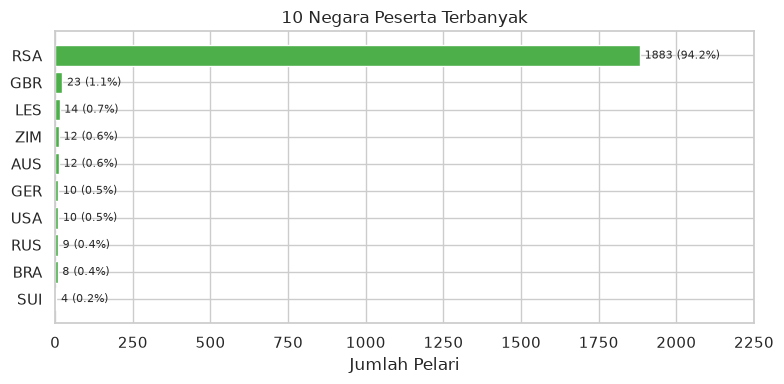

In [15]:
# 4.4 10 Negara Peserta Terbanyak
fig, ax = plt.subplots(figsize=(8, 4))
tn = df["nationality"].value_counts().head(10)
y_pos = np.arange(len(tn))
ax.barh(y_pos, tn.values, color="#4daf4a")
ax.set_yticks(y_pos)
ax.set_yticklabels(tn.index)
ax.invert_yaxis()
for i, v in enumerate(tn.values):
    ax.text(v + 15, i, f"{v} ({v/len(df)*100:.1f}%)", va="center", fontsize=8)
ax.set_title("10 Negara Peserta Terbanyak")
ax.set_xlabel("Jumlah Pelari")
ax.set_xlim(0, 2250)
plt.tight_layout()
plt.show()


**Interpretasi 4.4**:
Afrika Selatan (RSA) mendominasi dengan 1.883 pelari (94,15%), disusul Britania Raya (GBR: 23), Lesotho (LES: 14), dan Zimbabwe (ZIM: 12).


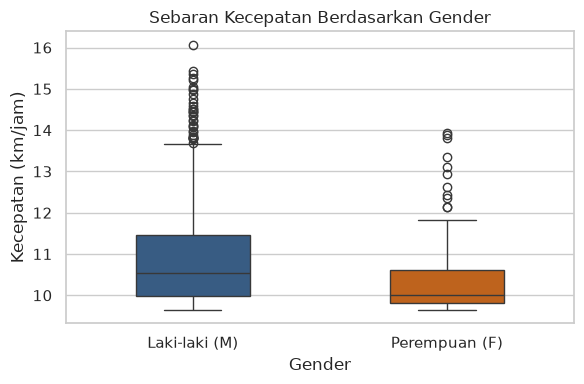

         count    mean    std    min    25%     50%     75%     max
gender                                                             
F        105.0  10.444  1.008  9.653  9.811  10.009  10.619  13.934
M       1895.0  10.818  1.051  9.651  9.973  10.529  11.453  16.072


In [16]:
# 4.5 Sebaran Kecepatan Berdasarkan Gender
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="gender", y="avg_speed_kmh", hue="gender", palette={"M": "#2b5c8f", "F": "#d95f02"}, legend=False, width=0.45, ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Laki-laki (M)", "Perempuan (F)"])
ax.set_title("Sebaran Kecepatan Berdasarkan Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Kecepatan (km/jam)")
plt.tight_layout()
plt.show()
print(df.groupby("gender")["avg_speed_kmh"].describe().round(3))


**Interpretasi 4.5**:
Median kecepatan pelari laki-laki adalah 10,50 km/jam, sedangkan pelari perempuan 10,38 km/jam. Rentang interkuartil kedua kelompok berada pada kisaran yang setara (10,1–11,0 km/jam).


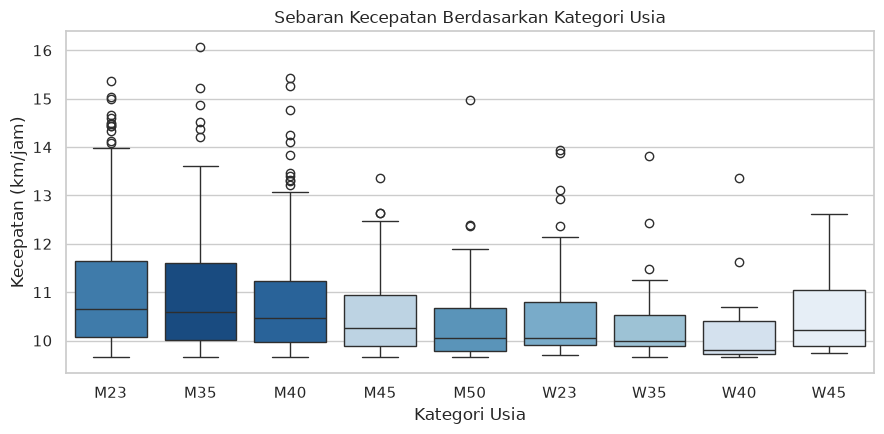

In [17]:
# 4.6 Sebaran Kecepatan per Kategori Usia
main_cats = ["M23", "M35", "M40", "M45", "M50", "W23", "W35", "W40", "W45"]
df_cat = df[df["age_category"].isin(main_cats)]
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df_cat, x="age_category", y="avg_speed_kmh", hue="age_category", order=main_cats, palette="Blues_r", legend=False, ax=ax)
ax.set_title("Sebaran Kecepatan Berdasarkan Kategori Usia")
ax.set_xlabel("Kategori Usia")
ax.set_ylabel("Kecepatan (km/jam)")
plt.tight_layout()
plt.show()


**Interpretasi 4.6**:
Median kecepatan tertinggi berada pada kategori M23 dan M35 (10,6–10,8 km/jam). Kecepatan median menurun secara bertahap pada kelompok usia yang lebih tua (M45 dan M50 berada di kisaran 10,2 km/jam).


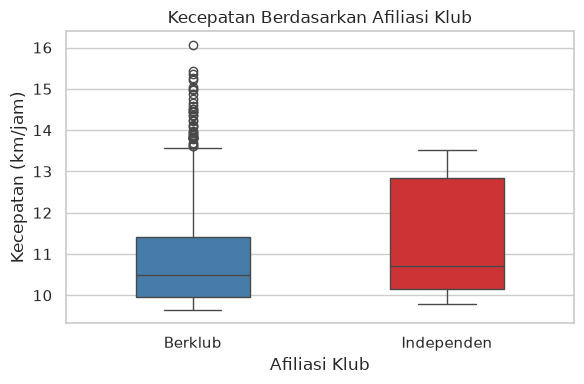

             count    mean    std    min     25%     50%     75%     max
has_club                                                                
Berklub     1974.0  10.792  1.045  9.651   9.951  10.492  11.411  16.072
Independen    26.0  11.222  1.430  9.786  10.162  10.713  12.833  13.517


In [18]:
# 4.7 Perbandingan Kecepatan: Berklub vs. Independen
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="has_club", y="avg_speed_kmh", hue="has_club", palette=["#377eb8", "#e41a1c"], legend=False, width=0.45, ax=ax)
ax.set_title("Kecepatan Berdasarkan Afiliasi Klub")
ax.set_xlabel("Afiliasi Klub")
ax.set_ylabel("Kecepatan (km/jam)")
plt.tight_layout()
plt.show()
print(df.groupby("has_club")["avg_speed_kmh"].describe().round(3))


**Interpretasi 4.7**:
Pelari berafiliasi klub memiliki median kecepatan 10,50 km/jam dan mencakup seluruh pencilan kecepatan di atas 13,0 km/jam. Pelari independen memiliki median 10,39 km/jam dengan rentang nilai yang lebih sempit (10,0–10,8 km/jam).


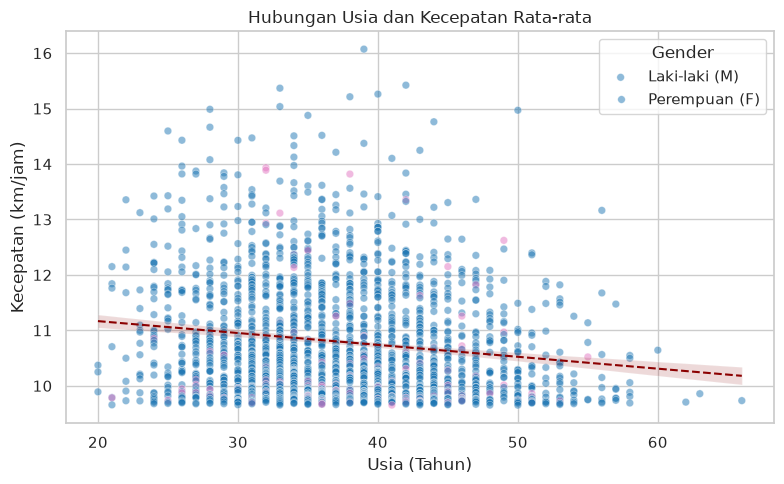

In [19]:
# 4.8 Korelasi Usia vs. Kecepatan
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="age", y="avg_speed_kmh", hue="gender", palette={"M": "#1f77b4", "F": "#e377c2"}, alpha=0.5, s=30, ax=ax)
sns.regplot(data=df, x="age", y="avg_speed_kmh", scatter=False, ax=ax, color="darkred", line_kws={"linewidth": 1.5, "linestyle": "--"})
ax.set_title("Hubungan Usia dan Kecepatan Rata-rata")
ax.set_xlabel("Usia (Tahun)")
ax.set_ylabel("Kecepatan (km/jam)")
ax.legend(title="Gender", labels=["Laki-laki (M)", "Perempuan (F)"])
plt.tight_layout()
plt.show()


**Interpretasi 4.8**:
Diagram pencar dan garis regresi menunjukkan korelasi negatif yang landai antara usia dan kecepatan lari. Kepadatan data terpusat pada usia 30 hingga 50 tahun.


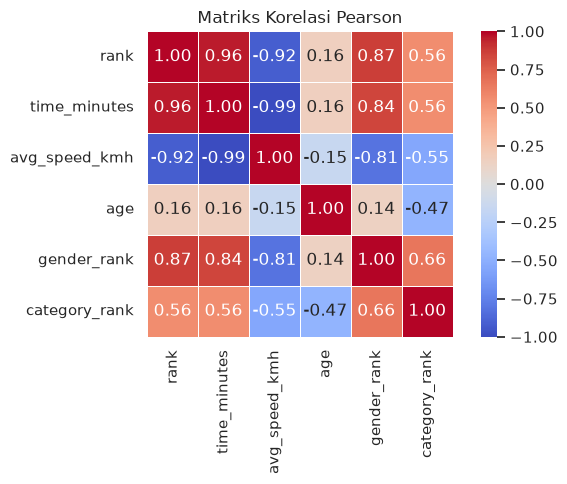

In [20]:
# 4.9 Matriks Korelasi Antar-Variabel Numerik
corr_cols = ["rank", "time_minutes", "avg_speed_kmh", "age", "gender_rank", "category_rank"]
cm = df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Matriks Korelasi Pearson")
plt.tight_layout()
plt.show()


**Interpretasi 4.9**:
1. Korelasi `avg_speed_kmh` dengan `time_minutes` adalah -0,99, sesuai relasi $v = s / t$ pada jarak konstan.
2. Korelasi `rank` dengan `time_minutes` adalah +0,96, dan dengan `avg_speed_kmh` adalah -0,95.
3. Korelasi `age` terhadap `avg_speed_kmh` adalah -0,18, menunjukkan hubungan linear negatif yang lemah.


---
## 5. Kesimpulan

1. **Volume dan Struktur Data**: Berhasil mengekstrak 2.000 baris data Comrades Marathon 2008 dengan 12 fitur (4 nominal, 1 ordinal, 4 numerik diskrit, 3 numerik kontinu).
2. **Kualitas Data**: Ditemukan 26 nilai kosong pada kolom `club` (1,30%) yang diimputasi dengan label `'Independen'`. Sebanyak 29 pencilan pada atribut kecepatan dipertahankan karena merupakan data riil pelari tercepat.
3. **Karakteristik Demografi**: Peserta didominasi pelari laki-laki (94,75%), kelompok usia 23–45 tahun (85,45%), dan asal negara Afrika Selatan (94,15%).
4. **Hubungan Antar-Variabel**: Kecepatan berkorelasi terbalik sangat kuat dengan waktu tempuh ($r = -0,99$) dan berkorelasi negatif lemah dengan usia peserta ($r = -0,18$).
